# A First Look at the Data

In this notebook we will have a first look at the H.E.S.S. public data set. More information on this data set can be found here: [https://www.mpi-hd.mpg.de/HESS/pages/dl3-dr1/](https://www.mpi-hd.mpg.de/HESS/pages/dl3-dr1/) . 

We will use gammapy ([https://gammapy.org/](https://gammapy.org/)) which heavily depends on astropy ([https://www.astropy.org/](https://www.astropy.org/)). We will see some data manipulation with numpy ([https://numpy.org/](https://numpy.org/)) and data presentation using matplotlib ([https://matplotlib.org/](https://matplotlib.org/)) and pyplot ([https://matplotlib.org/stable/tutorials/pyplot.html](https://matplotlib.org/stable/tutorials/pyplot.html)).

## Imports

Let's start with importing these modules.

In [1]:
import gammapy

In [2]:
gammapy.__version__

'2.1'

In [3]:
import numpy as np

In [4]:
np.__version__

'2.4.6'

In [5]:
import matplotlib
matplotlib.__version__

'3.10.9'

In [6]:
import matplotlib.pyplot as plt

## Download the data

Gammapy integrates the H.E.S.S. public data set in its tutorials. We can use gammapy to download the data easily.

In [7]:
from gammapy.utils.check import check_tutorials_setup

In [8]:
check_tutorials_setup()

279MB [00:45, 6.49MB/s]                                                                                                                                                                    



*** You might want to declare GAMMAPY_DATA as a global env variable
export GAMMAPY_DATA=$PWD/gammapy-data/2.1

Or as part of your conda environment:
conda env config vars set GAMMAPY_DATA=$PWD/gammapy-data/2.1
conda activate gammapy-2.1


System:

	python_executable      : /home/Mckie/.conda/envs/gammapy-2.1/bin/python 
	python_version         : 3.12.13    
	machine                : x86_64     
	system                 : Linux      


Gammapy package:

	version                : 2.1        
	path                   : /home/Mckie/.conda/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy 


Other packages:

	numpy                  : 2.4.6      
	scipy                  : 1.17.1     
	astropy                : 7.2.0      
	regions                : 0.10       
	click                  : 8.2.1      
	PyYAML                 : 6.0.3      
	pydantic               : 2.12.5     
	IPython                : 9.11.0     
	jupyter                : 1.1.1      
	jupyterlab             : 4.5.10     
	matpl

In [9]:
import os

In [10]:
os.environ['GAMMAPY_DATA'] = 'gammapy-data/2.0.1'

All the essential information about the observations is found in a DataStore.

In [11]:
from gammapy.data import DataStore

In [12]:
data_store = DataStore.from_dir('/home/Mckie/Desktop/GAMMAPY_UFS/HESS_Analysis_with_Gammapy-main/gammapy-data/2.1/hess-dl3-dr1')#("$GAMMAPY_DATA/hess-dl3-dr1")

You might need to modify the path.

In [13]:
data_store.info()

Data store:
HDU index table:
BASE_DIR: /home/Mckie/Desktop/GAMMAPY_UFS/HESS_Analysis_with_Gammapy-main/gammapy-data/2.1/hess-dl3-dr1
Rows: 630
OBS_ID: 20136 -- 47829
HDU_TYPE: [np.str_('aeff'), np.str_('bkg'), np.str_('edisp'), np.str_('events'), np.str_('gti'), np.str_('psf')]
HDU_CLASS: [np.str_('aeff_2d'), np.str_('bkg_3d'), np.str_('edisp_2d'), np.str_('events'), np.str_('gti'), np.str_('psf_table')]


Observation table:
Observatory name: 'N/A'
Number of observations: 105



Expected output:

```
Data store:
HDU index table:
BASE_DIR: gammapy-data/1.2/hess-dl3-dr1
Rows: 630
OBS_ID: 20136 -- 47829
HDU_TYPE: ['aeff', 'bkg', 'edisp', 'events', 'gti', 'psf']
HDU_CLASS: ['aeff_2d', 'bkg_3d', 'edisp_2d', 'events', 'gti', 'psf_table']


Observation table:
Observatory name: 'N/A'
Number of observations: 105
```

## DataStore

In [14]:
data_store.obs_table

OBS_ID,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,OBJECT,RA_OBJ,DEC_OBJ,OFFSET_OBJ,ONTIME,LIVETIME,DEADC,TSTART,TSTOP,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,TELLIST,QUALITY,MUONEFF,EVENT_COUNT,TARGET_NAME,TARGET_TAG,TARGET_OFFSET,SAFE_ENERGY_LO,SAFE_ENERGY_HI
,deg,deg,deg,deg,deg,deg,deg,,deg,deg,deg,s,s,,s,s,,,,,,,,,,,,deg,TeV,TeV
int64,float32,float32,float32,float32,float32,float32,float32,bytes18,float32,float32,float32,float32,float32,float32,float64,float64,bytes10,bytes12,bytes10,bytes12,int64,bytes7,int64,float32,int64,bytes21,bytes14,float32,float32,float32
20136,228.6125,-58.771667,320.56754,-0.8857012,38.512962,51.487038,195.73102,MSH15-52,228.6125,-59.271667,0.5,1682.0,1521.0269,0.9042966,101962602.0,101964284.0,2004-03-26,02:57:46.184,2004-03-26,03:25:48.184,4,"1,2,3,4",0,1.2132596,11243,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20137,228.6125,-59.771667,320.04724,-1.7397733,40.21616,49.78384,199.6482,MSH15-52,228.6125,-59.271667,0.5,902.0,819.2054,0.90821,101964441.0,101965343.0,2004-03-26,03:28:25.184,2004-03-26,03:43:27.184,4,"1,2,3,4",0,1.2139559,5693,MSH 15-52,msh1552,0.6156251,0.40738028,100.0
20151,228.6125,-58.771667,320.56754,-0.8857012,37.164658,52.835342,190.97171,custom,228.6125,-59.271667,0.5,1683.0,1530.479,0.9093755,102047232.0,102048915.0,2004-03-27,02:28:16.184,2004-03-27,02:56:19.184,4,"1,2,3,4",0,1.2214733,10722,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20275,187.27792,2.552389,289.7155,64.849686,36.18243,53.81757,49.144917,3C 273,187.27792,2.052389,0.5,1683.0,1525.8447,0.90662193,103665036.0,103666719.0,2004-04-14,19:51:40.184,2004-04-14,20:19:43.184,4,"1,2,3,4",0,1.121256,10646,Off data,offdata,--,0.33113113,100.0
20282,228.6125,-58.771667,320.56754,-0.8857012,37.13134,52.86866,169.21602,MSH 15-5-02,228.6125,-59.271667,0.5,1687.0,1543.3231,0.9148329,103678269.0,103679956.0,2004-04-14,23:32:13.184,2004-04-15,00:00:20.184,4,"1,2,3,4",0,1.1495326,11063,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20283,228.6125,-59.771667,320.04724,-1.7397733,36.221436,53.778564,175.77263,MSH 15-5-02,228.6125,-59.271667,0.5,1683.0,1547.8253,0.9196823,103680087.0,103681770.0,2004-04-15,00:02:31.184,2004-04-15,00:30:34.184,4,"1,2,3,4",0,1.1512518,7628,MSH 15-52,msh1552,0.6156251,0.3801894,100.0
20301,228.6125,-58.771667,320.56754,-0.8857012,36.839905,53.160095,171.07347,MSH 15-5-02,228.6125,-59.271667,0.5,1683.0,1534.0626,0.9115048,103764878.0,103766561.0,2004-04-15,23:35:42.184,2004-04-16,00:03:45.184,4,"1,2,3,4",0,1.1503073,11624,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20302,228.6125,-59.771667,320.04724,-1.7397733,36.11632,53.88368,177.10521,MSH 15-5-02,228.6125,-59.271667,0.5,1682.0,1535.3478,0.9128108,103766698.0,103768380.0,2004-04-16,00:06:02.184,2004-04-16,00:34:04.184,4,"1,2,3,4",0,1.1493496,11794,MSH 15-52,msh1552,0.6156251,0.3801894,100.0


This is an astropy.Table ([https://docs.astropy.org/en/stable/table/index.html](https://docs.astropy.org/en/stable/table/index.html)). Have look, these tables are very powerful.

In [15]:
data_store.obs_table.colnames

['OBS_ID',
 'RA_PNT',
 'DEC_PNT',
 'GLON_PNT',
 'GLAT_PNT',
 'ZEN_PNT',
 'ALT_PNT',
 'AZ_PNT',
 'OBJECT',
 'RA_OBJ',
 'DEC_OBJ',
 'OFFSET_OBJ',
 'ONTIME',
 'LIVETIME',
 'DEADC',
 'TSTART',
 'TSTOP',
 'DATE-OBS',
 'TIME-OBS',
 'DATE-END',
 'TIME-END',
 'N_TELS',
 'TELLIST',
 'QUALITY',
 'MUONEFF',
 'EVENT_COUNT',
 'TARGET_NAME',
 'TARGET_TAG',
 'TARGET_OFFSET',
 'SAFE_ENERGY_LO',
 'SAFE_ENERGY_HI']

In [16]:
np.unique(data_store.obs_table['OBJECT'])

array([b'00:29:18 -73:00:00', b'00:35:50 -71:41:20', b'1ES 0145+138',
       b'1ES 0414+009', b'1ES 2343-151', b'3C 120', b'3C 273',
       b'47 Tuc NW', b'AE Aqr', b'Arp 220', b'Cen A', b'Crab Nebula',
       b'EXO 0556.4-3838', b'G346.1+0.0', b'G346.8+0.0', b'G347.5+0.0',
       b'GRB 040425 north', b'GX 339-4', b'Kepler SNR', b'MSH 15-5-02',
       b'MSH15-52', b'NGC 1068', b'NGC 1399', b'NGC 253', b'PKS 0548-322',
       b'PKS 2155-304', b'PKS 2316-423', b'PSR J0437-4715', b'Pictor A',
       b'Q J22548-2725', b'RXJ 1713.7-3946', b'SN 1006', b'SN 1987A',
       b'Sco X-1', b'custom'], dtype='|S18')

The next table serves as an address book of sorts for the various files commonly used in gamma-ray analysis. 

File types:
- aeff, effective area IRf, function of true energy and offset angle from centre of FoV
- bkg, background IRF, background rate per solid angle, function on reconstructed energy and position in FoV)
- edisp, energy dispersion IRF, probability density of energy offset between true and reconstructed direction, function of true energy and offset angle from centre of FoV
- psf, point spread function IRF, probability density of angular offset between true and reconstructed direction, function of true energy and offset angle from centre of FoV
- events, event list, stores reconstructed direction and energy and the trigger times (shown later in this notebook)
- gti, good time interval, start and stop times of each run

With most internal H.E.S.S. observational data productions, these files do not always point to the same fits file; for example, you might not have a background file at all, with separate remaining IRFs.

In [17]:
data_store.hdu_table

OBS_ID,HDU_TYPE,HDU_CLASS,FILE_DIR,FILE_NAME,HDU_NAME,SIZE
int64,bytes6,bytes9,bytes4,bytes34,bytes6,int64
20136,aeff,aeff_2d,data,hess_dl3_dr1_obs_id_020136.fits.gz,aeff,11520
20136,bkg,bkg_3d,data,hess_dl3_dr1_obs_id_020136.fits.gz,bkg,207360
20136,edisp,edisp_2d,data,hess_dl3_dr1_obs_id_020136.fits.gz,edisp,377280
20136,events,events,data,hess_dl3_dr1_obs_id_020136.fits.gz,events,414720
20136,gti,gti,data,hess_dl3_dr1_obs_id_020136.fits.gz,gti,5760
20136,psf,psf_table,data,hess_dl3_dr1_obs_id_020136.fits.gz,psf,118080
20137,aeff,aeff_2d,data,hess_dl3_dr1_obs_id_020137.fits.gz,aeff,11520
20137,bkg,bkg_3d,data,hess_dl3_dr1_obs_id_020137.fits.gz,bkg,207360
20137,edisp,edisp_2d,data,hess_dl3_dr1_obs_id_020137.fits.gz,edisp,377280


## Run Selection

In [40]:
import astropy.units as u
from astropy.coordinates import SkyCoord, Angle

We set the source position. frame='icrs' indicates that we are using coordinates in right ascension and declination.

In [41]:
source_pos = SkyCoord(83.633*u.deg, 22.014*u.deg, frame='icrs')

In [42]:
selectradius = 2.5*u.deg

In [43]:
conesearch = data_store.obs_table.select_sky_circle(source_pos, selectradius)

In [44]:
conesearch

OBS_ID,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,OBJECT,RA_OBJ,DEC_OBJ,OFFSET_OBJ,ONTIME,LIVETIME,DEADC,TSTART,TSTOP,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,TELLIST,QUALITY,MUONEFF,EVENT_COUNT,TARGET_NAME,TARGET_TAG,TARGET_OFFSET,SAFE_ENERGY_LO,SAFE_ENERGY_HI
,deg,deg,deg,deg,deg,deg,deg,,deg,deg,deg,s,s,,s,s,,,,,,,,,,,,deg,TeV,TeV
int64,float32,float32,float32,float32,float32,float32,float32,bytes18,float32,float32,float32,float32,float32,float32,float64,float64,bytes10,bytes12,bytes10,bytes12,int64,bytes7,int64,float32,int64,bytes21,bytes14,float32,float32,float32
23523,83.63333,21.514444,184.9823,-6.0516925,48.61021,41.38979,22.481705,Crab Nebula,83.63333,22.014444,0.5,1687.0,1581.7368,0.9376033,123890826.0,123892513.0,2004-12-04,22:08:10.184,2004-12-04,22:36:17.184,4,"1,2,3,4",0,0.9070748,7613,Crab,crab,0.500049,0.8709636,100.0
23526,83.63333,22.514444,184.13332,-5.5163794,45.77929,44.22071,8.542603,Crab Nebula,83.63333,22.014444,0.5,1683.0,1572.6868,0.9344544,123893580.0,123895263.0,2004-12-04,22:54:04.184,2004-12-04,23:22:07.184,4,"1,2,3,4",0,0.9142412,7581,Crab,crab,0.49995112,0.70794576,100.0
23559,85.253334,22.014444,185.35727,-4.510869,45.368176,44.631824,2.2535799,Crab Nebula,83.63333,22.014444,1.5018803,1686.0,1578.1235,0.9360163,124067051.0,124068737.0,2004-12-06,23:05:15.184,2004-12-06,23:33:21.184,4,"1,2,3,4",0,0.91964024,7601,Crab,crab,1.5021166,0.66069347,100.0
23592,82.013336,22.014444,183.7408,-7.047852,48.389248,41.610752,21.7556,Crab Nebula,83.63333,22.014444,1.5018733,1686.0,1581.2646,0.9378794,124235636.0,124237322.0,2004-12-08,21:55:00.184,2004-12-08,22:23:06.184,4,"1,2,3,4",0,0.9120389,7334,Crab,crab,1.5016365,0.8709636,100.0


In [45]:
runlist = conesearch['OBS_ID'].value

In [46]:
print(runlist)

[23523 23526 23559 23592]


In [47]:
len(runlist)

4

In [48]:
observations = data_store.get_observations(runlist)

In [49]:
observations.ids

['23523', '23526', '23559', '23592']

In [50]:
obs = observations[0]

In [51]:
obs.obs_id

23523

In [52]:
obs

## Event Lists

The most information is found in the event list. It is simply a list of recorded events. Remember, we measure indivual gamma-ray photons.

In [53]:
from gammapy.data import EventList

In [54]:
events = obs.events

In [55]:
events

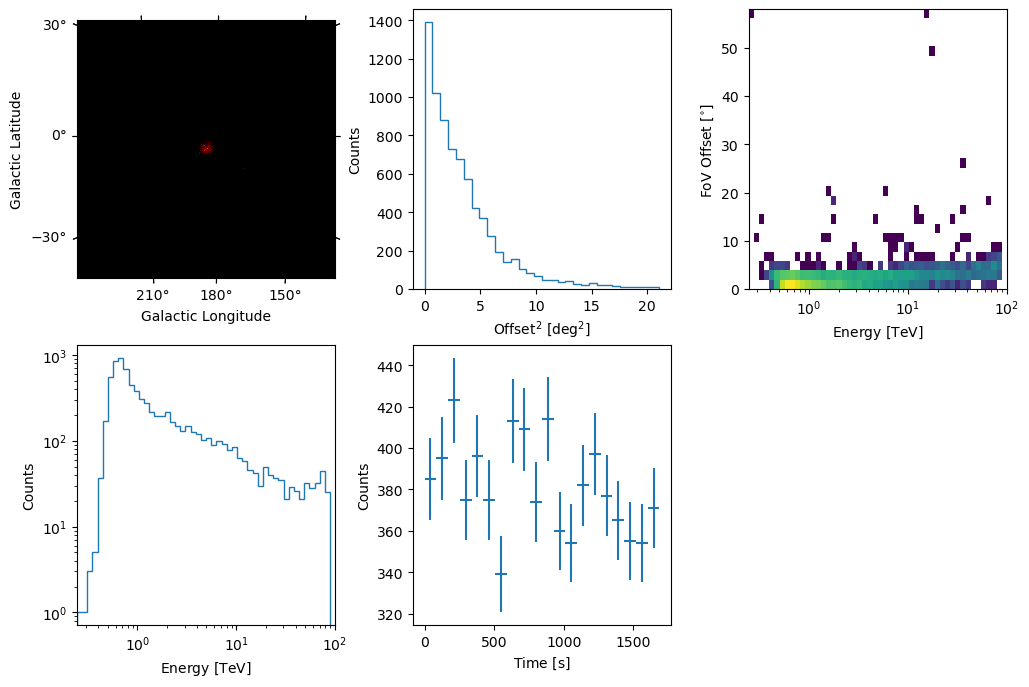

In [56]:
events.peek()

In [57]:
events.table

TIME,ENERGY,RA,DEC,EVENT_ID
,TeV,deg,deg,
Time,float32,float32,float32,int64
53343.92234782471,10.352011,84.97964,23.89347,5407363825684
53343.922348165426,4.0246882,84.54751,21.004095,5407363825695
53343.922354406706,2.2048872,85.39696,19.41868,5407363825831
53343.92236088141,0.69548655,81.93147,20.79867,5407363825970
53343.922366265215,0.86911184,85.98302,21.053099,5407363826067
53343.92236803166,4.1240892,86.97305,21.837437,5407363826095
53343.92236932359,1.6680022,83.40073,19.771587,5407363826128
53343.92237114528,4.7649446,82.25036,19.22003,5407363826168


(array([[0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
         0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00],
        [1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
         0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00],
        [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
         0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00],
        [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
         1.000e+00, 0.000e+00, 0.000e+00, 1.000e+00],
        [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
         0.000e+00, 0.000e+00, 3.000e+00, 2.000e+00],
        [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 2.000e+00,
         7.000e+00, 1.264e+03, 1.245e+03, 4.000e+00],
        [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 2.000e+00,
         1.000e+01, 2.438e+03, 2.615e+03, 7.000e+00],
        [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
         1.000e+00, 2.

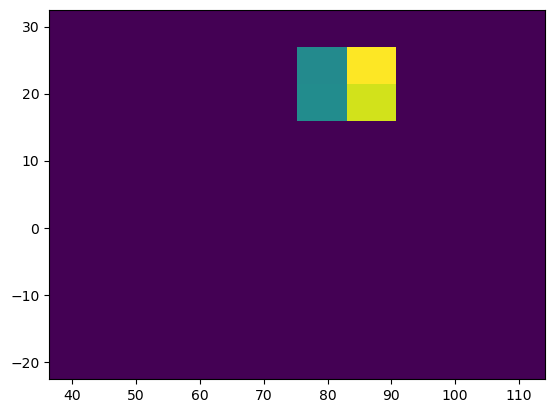

In [58]:
plt.hist2d(events.table['RA'], 
           events.table['DEC'], 
           #bins = [100,100]
          )

(array([6.957e+03, 2.730e+02, 1.230e+02, 5.800e+01, 4.700e+01, 4.800e+01,
        3.600e+01, 5.200e+01, 1.800e+01, 1.000e+00]),
 array([  0.24408458,  10.31748867,  20.39089394,  30.46429825,
         40.53770065,  50.61110306,  60.68450928,  70.75791931,
         80.83132172,  90.90472412, 100.97813416]),
 <BarContainer object of 10 artists>)

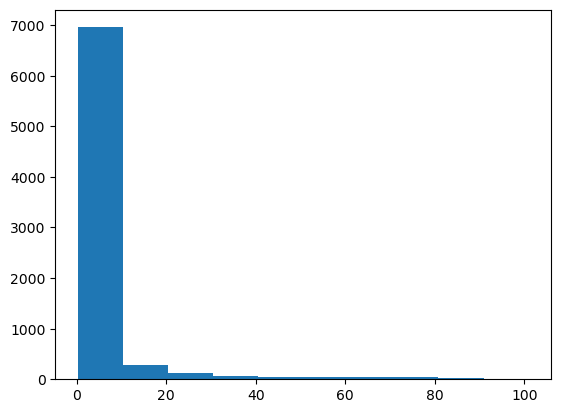

In [59]:
plt.hist(events.table['ENERGY'],
         #log = True,
         #range = [0.1,100],
         #bins = 100,
        )

## Theta$^2$ Plot

### on-source counts

In [60]:
events.radec

<SkyCoord (ICRS): (ra, dec) in deg
    [(84.97964, 23.89347 ), (84.54751, 21.004095), (85.39696, 19.41868 ),
     ..., (81.45052, 22.960012), (84.41192, 21.330505),
     (84.47432, 21.634737)]>

In [61]:
first_event = events.radec[0]

In [62]:
first_event

<SkyCoord (ICRS): (ra, dec) in deg
    (84.97964, 23.89347)>

In [63]:
first_event.separation(source_pos)

<Angle 2.25162431 deg>

In [64]:
theta2 = events.radec.separation(source_pos)**2

In [65]:
print(theta2)

[5.06981204 1.74377617 9.45718502 ... 4.96113965 0.9911266  0.7538281 ] deg2


Text(0.5, 0, '$\\theta^2$ [deg$^2$]')

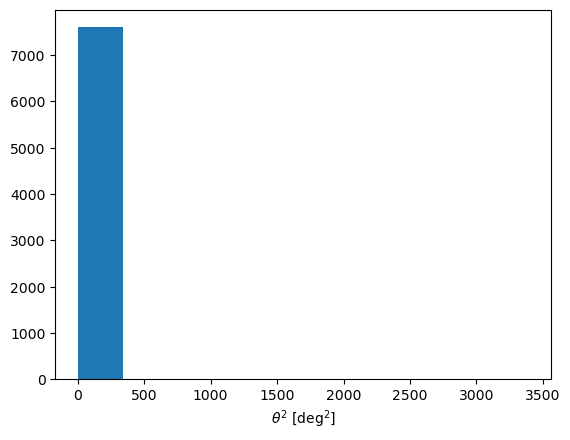

In [66]:
ret = plt.hist(theta2.value, 
               #range = [0,0.1], 
               #bins = 50
              )

plt.xlabel('$\\theta^2$ [deg$^2$]')

#plt.savefig('Theta2_on.svg')

In [67]:
ret

(array([7.606e+03, 4.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 2.000e+00]),
 array([1.05483675e-04, 3.39271731e+02, 6.78543357e+02, 1.01781498e+03,
        1.35708661e+03, 1.69635823e+03, 2.03562986e+03, 2.37490149e+03,
        2.71417311e+03, 3.05344474e+03, 3.39271636e+03]),
 <BarContainer object of 10 artists>)

In [68]:
n = ret[0]
x = ret[1]

In [69]:
print(x)

[1.05483675e-04 3.39271731e+02 6.78543357e+02 1.01781498e+03
 1.35708661e+03 1.69635823e+03 2.03562986e+03 2.37490149e+03
 2.71417311e+03 3.05344474e+03 3.39271636e+03]


In [70]:
x[1:]<0.01

array([False, False, False, False, False, False, False, False, False,
       False])

In [71]:
n[ x[1:]<0.01 ]

array([], dtype=float64)

In [72]:
oncounts = n[x[1:]<0.01].sum()

In [73]:
oncounts

np.float64(0.0)

### off-source counts

In [74]:
print(obs)

Observation

	obs id            : 23523 
 	tstart            : 53343.92
	tstop             : 53343.94
	duration          : 1687.00 s
	pointing (icrs)   : 83.6 deg, 21.5 deg

	deadtime fraction : 6.2%



In [75]:
pointing_pos = obs.pointing.fixed_icrs

In [76]:
pointing_pos

<SkyCoord (ICRS): (ra, dec) in deg
    (83.63333333, 21.51444444)>

In [77]:
separation = pointing_pos.separation(source_pos)
print (separation)

0d29m58.40034531s


In [78]:
position_angle = pointing_pos.position_angle(source_pos)
print (position_angle.to(u.deg))

359d57m52.40063811s


In [79]:
offpos = pointing_pos.directional_offset_by( position_angle+180*u.deg, separation)

In [80]:
offpos

<SkyCoord (ICRS): (ra, dec) in deg
    (83.63366438, 21.01488889)>

In [81]:
theta2_off = events.radec.separation(offpos)**2

Text(0.5, 0, '$\\theta^2$ [deg$^2$]')

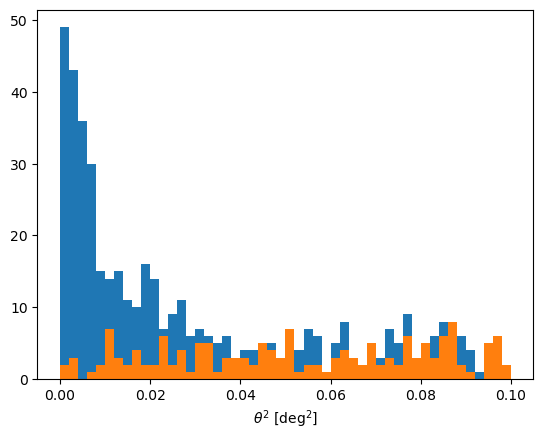

In [82]:
plt.hist(theta2.value, range = [0,0.1], bins = 50)

ret_off = plt.hist(theta2_off.value, 
                   range = [0,0.1], 
                   bins = 50, 
                   #alpha = 0.5
                  )

plt.xlabel('$\\theta^2$ [deg$^2$]')

#plt.savefig('Theta2_onoff.svg')

In [83]:
n_off = ret_off[0]
x_off = ret_off[1]
offcounts = n_off[x_off[1:]<0.01].sum()

In [84]:
print(oncounts,offcounts)

0.0 6.0


### excess

In [85]:
excess = oncounts - offcounts

In [86]:
excess

np.float64(-6.0)

### background check

Let's check that there is no excess at larger $\theta^2$ values, where we do not expect any emission.

In [87]:
x[1:] > 0.05

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

In [88]:
check_on = n[x[1:]>0.05].sum()

In [89]:
check_off = n_off[x_off[1:]>0.05].sum()

In [90]:
print('{} - {} = {}'.format(check_on, check_off, check_on - check_off))

7613.0 - 84.0 = 7529.0


### Significance

In [91]:
total = oncounts + offcounts

In [92]:
total

np.float64(6.0)

In [93]:
from numpy import sqrt

In [94]:
sigma = sqrt(total)

In [95]:
sigma

np.float64(2.449489742783178)

In [96]:
significance_1 = excess/sigma

In [97]:
significance_1

np.float64(-2.4494897427831783)

In [98]:
from gammapy.stats import WStatCountsStatistic

In [99]:
stat = WStatCountsStatistic(n_on=oncounts, n_off=offcounts, alpha=1.)

print('excess: {} \nsignificance: {}'.format(stat.n_sig,stat.sqrt_ts))

excess: -6.0 
significance: -2.8840537732017664


Let's check the background:

In [100]:
stat_check = WStatCountsStatistic(n_on=check_on, n_off=check_off, alpha=1.)

print('excess: {} \nsignificance: {}'.format(stat_check.n_sig,stat_check.sqrt_ts))

excess: 7529.0 
significance: 98.71293004908019


### Your playground

If you want to do it yourself, try the following.

Make a theta^2 plot for signal and background for the second observation run. Calculate the number of on and off events for a theta^2 cut of 0.02. Calculate the significance.

In [101]:
## your code here

### Combine all runs
We will no use some gammapy code to prepare the $\theta^2$ plot for all runs combined. First we will define the x-axis:

In [102]:
from gammapy.maps import MapAxis

In [103]:
theta2_axis = MapAxis.from_bounds(0, 0.1, 
                                  nbin=40, 
                                  unit='deg2'
                                 )

In [104]:
theta2_axis.edges

<Quantity [0.    , 0.0025, 0.005 , 0.0075, 0.01  , 0.0125, 0.015 , 0.0175,
           0.02  , 0.0225, 0.025 , 0.0275, 0.03  , 0.0325, 0.035 , 0.0375,
           0.04  , 0.0425, 0.045 , 0.0475, 0.05  , 0.0525, 0.055 , 0.0575,
           0.06  , 0.0625, 0.065 , 0.0675, 0.07  , 0.0725, 0.075 , 0.0775,
           0.08  , 0.0825, 0.085 , 0.0875, 0.09  , 0.0925, 0.095 , 0.0975,
           0.1   ] deg2>

In [105]:
from gammapy.makers.utils import make_theta_squared_table

In [106]:
theta2_table = make_theta_squared_table(observations=observations,
                                        position=source_pos,
                                        theta_squared_axis=theta2_axis
                                       )

/tmp/ipykernel_12773/4111954331.py:1: GammapyDeprecationWarning: The make_theta_squared_table function is deprecated and may be removed in a future version.
        Use ThetaSquaredTable instead.
  theta2_table = make_theta_squared_table(observations=observations,


In [107]:
theta2_table

theta2_min,theta2_max,counts,counts_off,acceptance,acceptance_off,alpha,excess,sqrt_ts,excess_errn,excess_errp
deg2,deg2,,,,,,,,,
float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64
0.0,0.0025,241,4.0,4.0,4.0,1.0,237.0,17.285487327203462,15.332810153644658,15.97752752205912
0.0025,0.005,173,9.0,4.0,4.0,1.0,164.0,13.440092027815513,13.195847135426447,13.795987633511885
0.005,0.0075,131,11.0,4.0,4.0,1.0,120.0,10.929515524511233,11.64291970486478,12.205241452156685
0.0075,0.01,92,10.0,4.0,4.0,1.0,82.0,8.715983648512772,9.84300067438275,10.377227502342464
0.01,0.0125,73,18.0,4.0,4.0,1.0,55.0,5.969658144966952,9.356946576397178,9.757339431747369
0.0125,0.015,66,20.0,4.0,4.0,1.0,46.0,5.092867266123762,9.11678402408782,9.4707152170458
0.015,0.0175,52,14.0,4.0,4.0,1.0,38.0,4.825344946024097,7.955640710693277,8.335983529894662
0.0175,0.02,49,11.0,4.0,4.0,1.0,38.0,5.099843077678653,7.557644966254404,7.976057503784503


In [108]:
all_on = theta2_table['counts'][theta2_table['theta2_max'] < 0.01].sum()

In [109]:
all_on

np.int64(545)

In [110]:
all_off = theta2_table['counts_off'][theta2_table['theta2_max'] < 0.01].sum()

In [111]:
all_off

np.float64(24.0)

In [112]:
all_excess = all_on - all_off

In [113]:
all_excess

np.float64(521.0)

In [114]:
stat_all = WStatCountsStatistic(n_on=all_on, n_off=all_off, alpha=1.)

print('excess: {} \nsignificance: {}'.format(stat_all.n_sig,stat_all.sqrt_ts))

excess: 521.0 
significance: 24.287211809532415


In [115]:
theta2_centre = theta2_axis.center.value

Text(0.5, 0, '$\\theta^2$ [deg$^2$]')

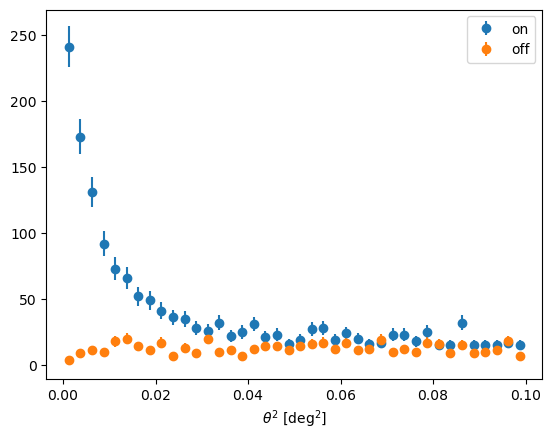

In [116]:
plt.errorbar(theta2_centre,
             theta2_table['counts'],
             sqrt(theta2_table['counts']),
             label = 'on',
             ls = 'none',
             marker = 'o'
            )

plt.errorbar(theta2_centre,
             theta2_table['counts_off'],
             sqrt(theta2_table['counts_off']),
             label = 'off',
             ls = 'none',
             marker = 'o'
            )

plt.legend()

plt.xlabel('$\\theta^2$ [deg$^2$]')

#plt.savefig('Theta2_all_onoff.svg')

Text(0.5, 0, '$\\theta^2$ [deg$^2$]')

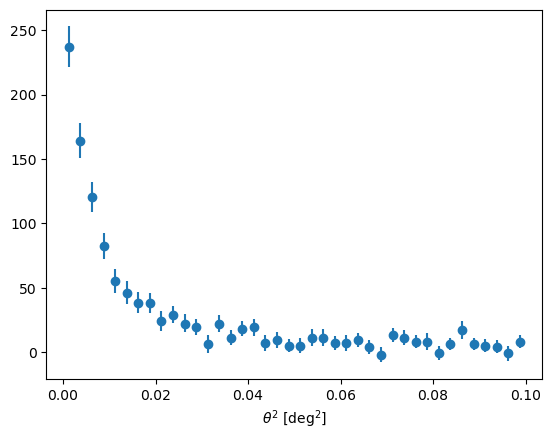

In [117]:
plt.errorbar(theta2_centre,
             theta2_table['excess'],
             [theta2_table['excess_errn'].data, theta2_table['excess_errp'].data],
             ls = 'none',
             marker = 'o'
            )

plt.xlabel('$\\theta^2$ [deg$^2$]')

#plt.savefig('Theta2_all_excess.svg')

In [118]:
from gammapy.visualization import plot_theta_squared_table

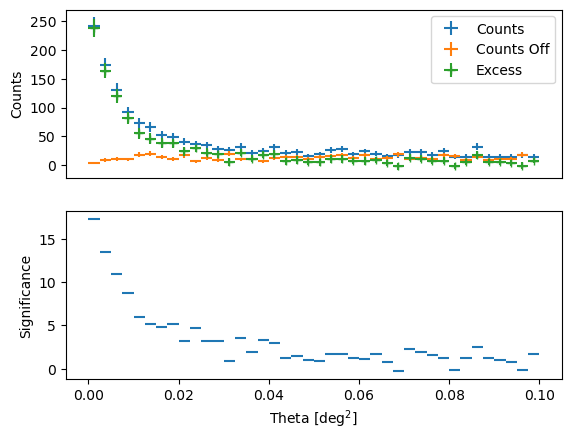

In [119]:
plot_theta_squared_table(theta2_table)

## Simple Counts Map

In [120]:
from gammapy.maps import Map

In [121]:
map_crab = Map.create(binsz=0.01*u.deg, 
                      width=(5*u.deg, 5*u.deg), 
                      skydir=source_pos, 
                      frame='icrs')

<WCSAxes: >

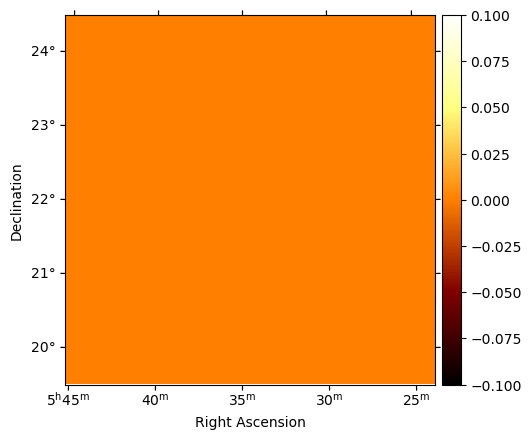

In [122]:
map_crab.plot(add_cbar = True)

In [123]:
events.radec

<SkyCoord (ICRS): (ra, dec) in deg
    [(84.97964, 23.89347 ), (84.54751, 21.004095), (85.39696, 19.41868 ),
     ..., (81.45052, 22.960012), (84.41192, 21.330505),
     (84.47432, 21.634737)]>

In [124]:
map_crab.fill_by_coord(events.radec)

<WCSAxes: >

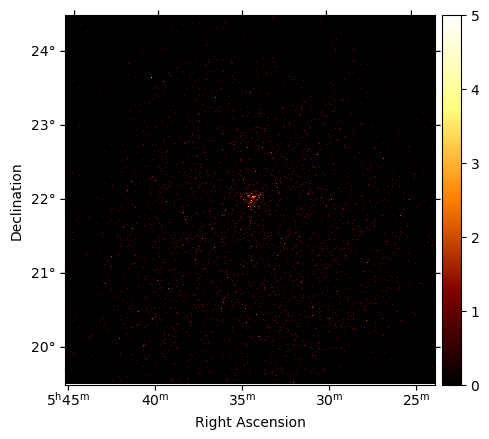

In [125]:
map_crab.plot(
    add_cbar = True,
#    cmap = 'plasma'
)

Find your favourite colour map here : [https://matplotlib.org/stable/users/explain/colors/colormaps.html](https://matplotlib.org/stable/users/explain/colors/colormaps.html)

In [126]:
smoothed = map_crab.smooth(width=0.05 * u.deg, kernel="gauss")

<WCSAxes: >

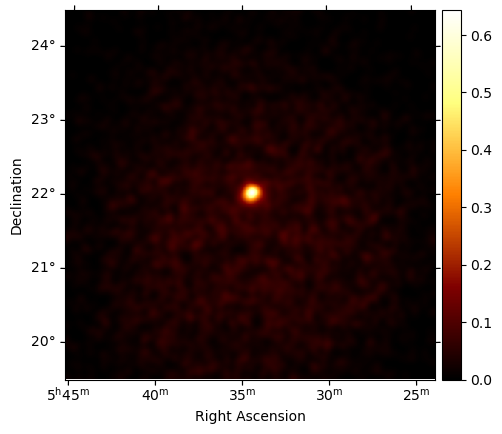

In [127]:
smoothed.plot(
    add_cbar=True,
#    cmap = 'plasma'
#    stretch="log", 
)

In [128]:
smoothed_1 = map_crab.smooth(width=0.2 * u.deg, kernel="gauss")

<WCSAxes: >

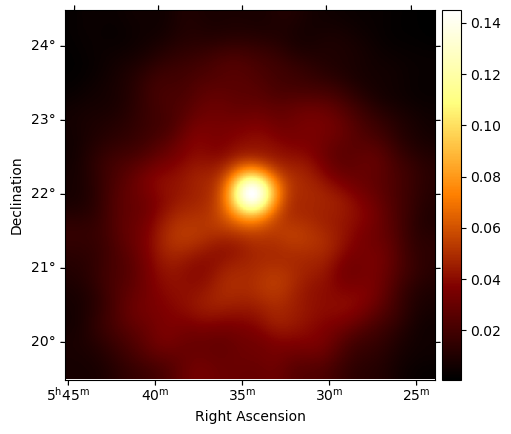

In [129]:
smoothed_1.plot(
    add_cbar=True,
#    cmap = 'plasma'
#    stretch="log", 
)

#### Your playground
Make a smoothed sky map. Make the map 3degx3deg large, and use a binning of 0.005deg. Smooth with a disk kernel with 0.03deg. Add a colour bar and stretch such that both the source and the background is clearly seen. You can also try different colour schemes, for example cmap='ocean_r'.

In [130]:
## your code here

## Summary

In this notebook we have seen how to download and select the data. We had a first look at the information found in the events list and how to make simple plots.